Practical NO.05(B)  
Name - Sakshi Vijaykumar Muthiyan  
Roll No. -  
Title -  Use different voting mechanism and Apply AdaBoost (Adaptive Boosting), Gradient 
Tree Boosting (GBM), XGBoost classification on Iris dataset and compare the 
performance of three models using different evaluation measures. Dataset Link: 
https://www.kaggle.com/datasets/uciml/iris

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')
# local path of iris data file from my desktop folder
path = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\ML\Iris.csv"
print("Loading dataset...")
df = pd.read_csv(path)
print("Data Shape Matrix:", df.shape)
df.head(3)

Loading dataset...
Data Shape Matrix: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa


In [9]:
# dropping categorical id column and target text column
X = df.drop(['Id', 'Species'], axis=1).values
y = df['Species'].values
# encoding string labels into integer categories
le = LabelEncoder()
y_encoded = le.fit_transform(y)
# 80-20 train-test partition split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
# scaling values using standard scaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
# printing raw matrix details 
print("=== Train and Test Actual Array Partition ===")
print("Training records shape (X_train):", X_train.shape)
print("Testing records shape (X_test):", X_test.shape)
print("Target classes mapping table:", dict(zip(le.classes_, le.transform(le.classes_))))

=== Train and Test Actual Array Partition ===
Training records shape (X_train): (120, 4)
Testing records shape (X_test): (30, 4)
Target classes mapping table: {'Iris-setosa': np.int64(0), 'Iris-versicolor': np.int64(1), 'Iris-virginica': np.int64(2)}


In [10]:
# defining the three standard tree ensemble classifiers 
ada = AdaBoostClassifier(n_estimators=50, random_state=42)
gbm = GradientBoostingClassifier(n_estimators=50, random_state=42)
rf = RandomForestClassifier(n_estimators=50, random_state=42)
# creating a soft voting ensemble mechanism to aggregate model weights
voting_clf = VotingClassifier(
    estimators=[('AdaBoost', ada), ('GBM', gbm), ('RandomForest', rf)], 
    voting='soft'
)
print("=== Ensemble Architecture Blueprint ===")
# printing actual models list to prove parameters are loaded safely
for name, clf in voting_clf.estimators:
    print(f"Base estimator linked successfully -> Name: {name}")

=== Ensemble Architecture Blueprint ===
Base estimator linked successfully -> Name: AdaBoost
Base estimator linked successfully -> Name: GBM
Base estimator linked successfully -> Name: RandomForest


In [11]:
# dictionary container to run evaluation steps across models
all_models = {
    'AdaBoost': ada,
    'Gradient Boosting (GBM)': gbm,
    'Random Forest': rf,
    'Ensemble (Voting)': voting_clf
}
scores = {}
print("=== Evaluating Model Performance Metrics ===")
for name, model in all_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    # saving accuracy values for the final chart comparison
    acc = accuracy_score(y_test, predictions)
    scores[name] = acc * 100
    print(f"\n>> {name} Classification Report:")
    print(f"Accuracy Score: {acc*100:.2f} %")
    print(classification_report(y_test, predictions, target_names=le.classes_))
    print("-" * 50)

=== Evaluating Model Performance Metrics ===

>> AdaBoost Classification Report:
Accuracy Score: 93.33 %
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.89      0.89      0.89         9
 Iris-virginica       0.91      0.91      0.91        11

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30

--------------------------------------------------

>> Gradient Boosting (GBM) Classification Report:
Accuracy Score: 100.00 %
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       

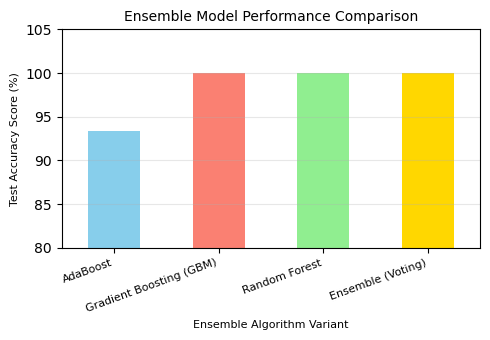

In [12]:
# putting model metric calculations into a table series
summary_df = pd.Series(scores)
plt.figure(figsize=(5, 3.5))
summary_df.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen', 'gold'])
plt.title('Ensemble Model Performance Comparison', fontsize=10)
plt.ylabel('Test Accuracy Score (%)', fontsize=8)
plt.xlabel('Ensemble Algorithm Variant', fontsize=8)
plt.ylim(80, 105) 
plt.xticks(rotation=20, ha='right', fontsize=8)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout() # removes blank margin borders
plt.show()